In [3]:
import warnings

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore")
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import auc, confusion_matrix, f1_score, recall_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import shuffle as sk_shuffle
from toolbox import (
    Masking,
    augment_patient_and_cat_specific,
    find_all_indices,
    hot_coding,
    visualize_Category_hist,
)
from toolbox.loading import load_data

In [4]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
# set prints off
mask.prints = False

## Contents

- SNR Data augmentation tuning
- Model tuning
    - SVM tuning
    - RF tuning
    - LR tuning



**Data loading**

In [5]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -6.353090079251737e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [25]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

data_augmentation = True

Healthy vs. cancer

Healthy: 90 entries
Cancer: 96 entries
Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}


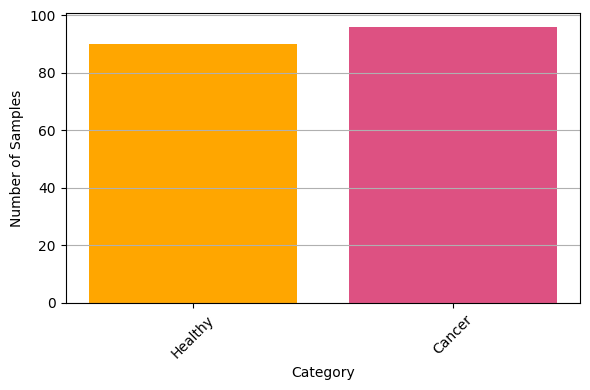


Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(186, 31, 7728) (186, 2) (186,)


In [26]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    # for SVD kernel boundary
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        1: "#003F5C",  # healthy
        0: "#FFA600",  # cancer
    }
    cp_l = {
        1: "healthy",  # healthy
        0: "cancer",  # cancer
    }
    visualize_Category_hist(labels)

elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        1: "#DD5182",  # non-cancer
        0: "#FFA600",  # cancer
    }
    cp_l = {
        1: "healthy",  # non-cancer
        0: "cancer",  # cancer
    }
    visualize_Category_hist(labels)

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "High-grade dysplasia", "Non-malignant"],
        split=False,
    )
    labels = labels_MC[select_idx]
    Y, inverse_mapping = hot_coding(labels)
    Y_labels = np.argmax(Y, axis=1)
    cp = {
        0: "#58508D",  # Non-malignant
        1: "#FFA600",  # Cancer
        2: "#003F5C",  # Healthy
        3: "#FF6361",  # High-grade dysplasia
    }
    cp_l = {
        0: "Non-malignant",
        1: "Cancer",
        2: "Healthy",
        3: "High-grade dysplasia",
    }
    aug_dict = {
        "High-grade dysplasia": 70,
        "Non-malignant": 70,
    }

Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

if class_task == "MC" and data_augmentation:
    print("\n\t\tBefore augmentation")
    visualize_Category_hist(labels)
    X, Y_labels, labels, Case = augment_patient_and_cat_specific(
        X, Y_labels, labels, Case, aug_dict
    )
    print("\n\t\tAfter augmentation")
    visualize_Category_hist(labels)

# Model tuning

**Tuning using `GridSearch()` with `GroupKFold()` train/test data split**

- SVM tuning
- RF tuning
- LR tuning

In [27]:
n_folds = 5  # number of iterations inside each LPOCV
output_prints = False

# load frequency selection
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]

Freq_sel = {
    "Top 2": top_freqs_baseline[:2],
    "Top 3": top_freqs_baseline[:3],
    "Top 5": top_freqs_baseline[:5],
    "Top 12": top_freqs_baseline[:12],
    # "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

# load masking selection
tmp = np.load(f"results/Top_IIVV_masks_{class_task}.npz", allow_pickle=True)
Mask_ranks = tmp["Mask_ranks"][:4]

Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}
Mask_sel = {k: v for k, v in Mask_sel.items() if k in Mask_ranks}

## SVM tuning

In [7]:
stats_df = []
use_model = "SVM"

param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
for Fsel in Freq_sel.keys():
    for Msel in Mask_sel.keys():
        for random_state in range(10):

            cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)
            """
            for fold, (train_idx, test_idx) in enumerate(cv.split(X_tmp, Y_labels, groups=Case), 1):
                print(f"Fold {fold}")
                print("  Train groups:", Case[train_idx])
                print("  Test groups :", Case[test_idx])
                print("  Train idx   :", train_idx)
                print("  Test idx    :", test_idx)
                print()
            """
            m = SVC(probability=True, random_state=random_state)

            grid_search = GridSearchCV(
                estimator=m,
                param_grid=param_grid,
                cv=cv,
                scoring="roc_auc_ovr",
                n_jobs=80,
            )

            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            # select freq and IIVV and shape data
            X_tmp = X[:, Freq_sel[Fsel], :]
            X_tmp = X_tmp[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

            grid_search.fit(X_tmp, Y_labels, groups=Case)

            best_params = grid_search.best_params_
            best_score = grid_search.best_score_

            if output_prints:
                print(f"\nRandom_state{random_state}")
                print("Best parameters:", best_params)
                print("Best ROC AUC:", best_score)

            df_row = {
                "Architecture": use_model,
                "Fsel": Fsel,
                "Msel": Msel,
                "n_params": X_tmp.shape[1],
                "Random_state": random_state,
                "val AUC": best_score,
            }
            df_row.update(best_params)
            stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_SVM_{class_task}.csv", index=False)

In [20]:
param_grid = {
    "kernel": ["linear", "poly", "rbf", "sigmoid"],
    "C": np.logspace(-3, 3, 7, dtype=float),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_SVM_{class_task}.csv")

In [21]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

   hpt_combinations   val AUC
0      linear_0.001  0.898472
1       linear_0.01  0.899856
2        linear_0.1  0.899323
3         poly_0.01  0.889944
4          poly_0.1  0.899926
5          poly_1.0  0.906809
6           rbf_0.1  0.898112
7           rbf_1.0  0.900217
8          rbf_10.0  0.905499
9        rbf_1000.0  0.899448
10      sigmoid_0.1  0.897404
11      sigmoid_1.0  0.901389

Column: hpt_combinations
hpt_combinations
rbf_10.0        64
linear_0.001    22
linear_0.1      15
rbf_1.0         13
linear_0.01     13
sigmoid_0.1      9
rbf_0.1          7
poly_0.1         6
poly_1.0         5
sigmoid_1.0      3
poly_0.01        2
rbf_1000.0       1
Name: count, dtype: int64


[Plot-svm-kernels](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_kernels.html#rbf-kernel)

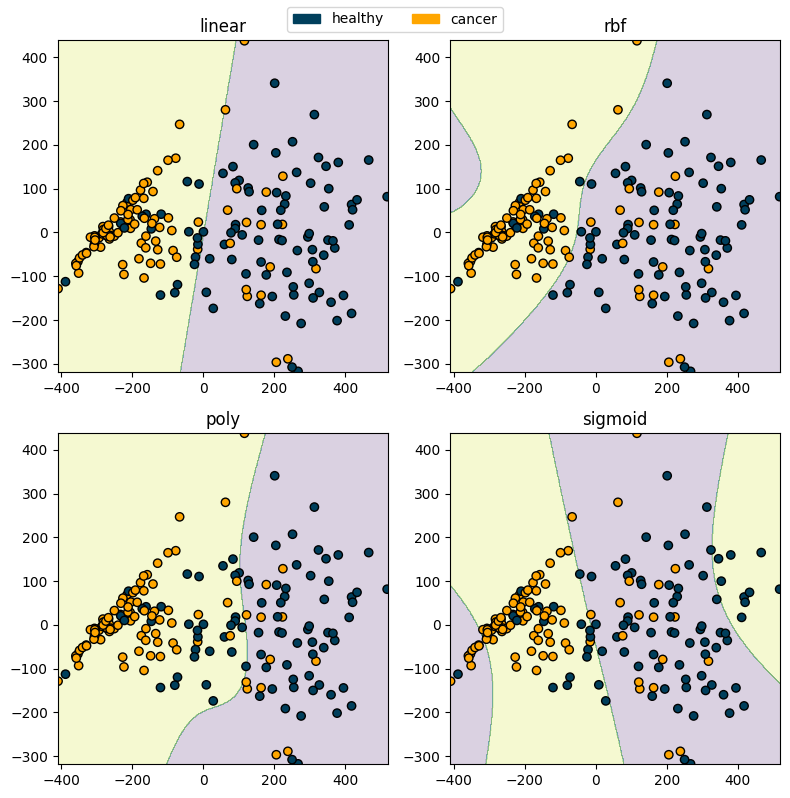

In [10]:
C_val = 10

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

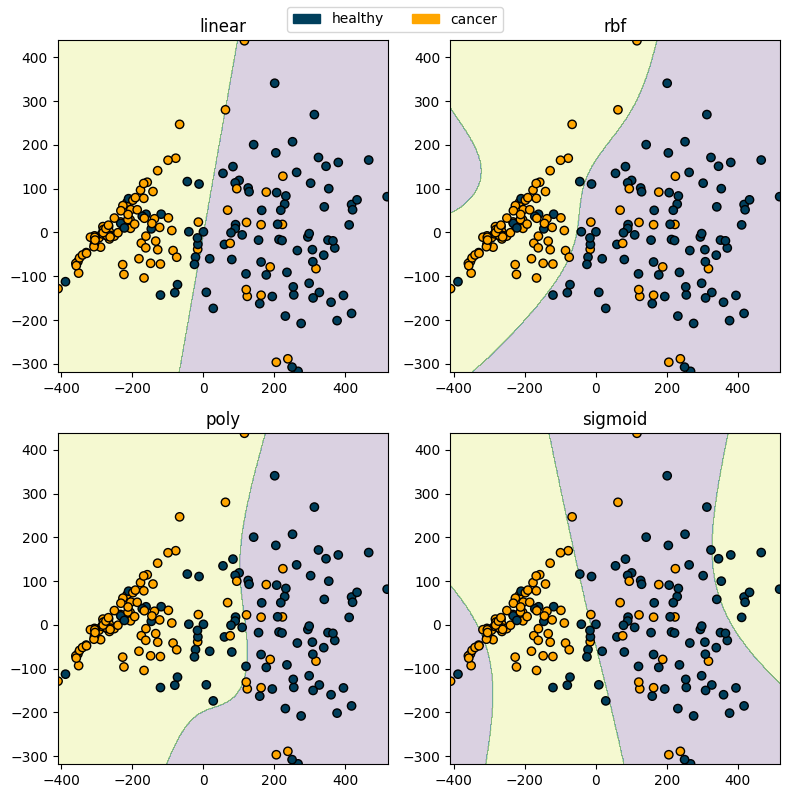

In [11]:
C_val = 1000

X_flat = X.reshape(X.shape[0], -1)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_flat)

kernels = ["linear", "rbf", "poly", "sigmoid"]
colors = [cp[label] for label in Y_labels]
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.ravel()
for i, kernel in enumerate(kernels):
    clf = SVC(kernel=kernel, C=10)
    clf.fit(X_2d, Y_labels)

    x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
    y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))

    Z = clf.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    axes[i].contourf(xx, yy, -1 * Z, alpha=0.2)
    scatter = axes[i].scatter(X_2d[:, 0], X_2d[:, 1], c=colors, edgecolor="k")
    axes[i].set_title(f"{kernel}")
    legend_handles = [mpatches.Patch(color=cp[k], label=cp_l[k]) for k in cp.keys()]
fig.legend(handles=legend_handles, loc="upper center", ncol=2, frameon=True)

plt.tight_layout()
plt.savefig(
    f"results/SVM_kernels_{class_task}_{C_val}.pdf",
    bbox_inches="tight",
)
plt.show()

## RF tuning

In [12]:
stats_df = []
use_model = "RF"

param_grid = {
    "n_estimators": [100, 300, 500, 800],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
for Fsel in Freq_sel.keys():
    for Msel in Mask_sel.keys():
        for random_state in range(10):
            cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

            m = RandomForestClassifier(random_state=random_state)

            grid_search = GridSearchCV(
                estimator=m,
                param_grid=param_grid,
                cv=cv,
                scoring="roc_auc_ovr",
                n_jobs=80,
            )
            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            # select freq and IIVV and shape data
            X_tmp = X[:, Freq_sel[Fsel], :]
            X_tmp = X_tmp[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

            grid_search.fit(X_tmp, Y_labels, groups=Case)

            best_params = grid_search.best_params_
            best_score = grid_search.best_score_

            if output_prints:
                print(f"\nRandom_state{random_state}")
                print("Best parameters:", best_params)
                print("Best ROC AUC:", best_score)

            df_row = {
                "Architecture": use_model,
                "Fsel": Fsel,
                "Msel": Msel,
                "n_params": X_tmp.shape[1],
                "Random_state": random_state,
                "val AUC": best_score,
            }
            df_row.update(best_params)
            stats_df.append(df_row)
df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_RF_{class_task}.csv", index=False)

In [22]:
param_grid = {
    "n_estimators": [100, 300, 500, 800],
    "max_depth": [510, 20, None],
    "max_features": ["sqrt", "log2"],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_RF_{class_task}.csv")

In [23]:
df

,Architecture,Fsel,Msel,n_params,Random_state,val AUC,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators
0,RF,Top 2,Adj. far,1320,0,0.920660,510,log2,4,2,300
1,RF,Top 2,Adj. far,1320,1,0.912996,510,log2,1,2,100
2,RF,Top 2,Adj. far,1320,2,0.925140,510,log2,1,5,500
3,RF,Top 2,Adj. far,1320,3,0.915027,510,log2,1,5,800
4,RF,Top 2,Adj. far,1320,4,0.927612,510,log2,2,5,800
...,...,...,...,...,...,...,...,...,...,...,...
155,RF,Top 12,Opp. medium,3168,5,0.905338,510,log2,2,5,100
156,RF,Top 12,Opp. medium,3168,6,0.912620,510,sqrt,1,2,100
157,RF,Top 12,Opp. medium,3168,7,0.904111,510,sqrt,2,10,300
158,RF,Top 12,Opp. medium,3168,8,0.914461,510,log2,1,2,300


In [24]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

     hpt_combinations   val AUC
0   100_510_log2_10_1  0.919323
1   100_510_log2_10_2  0.909067
2   100_510_log2_10_4  0.910338
3    100_510_log2_2_1  0.908727
4    100_510_log2_2_2  0.913217
5    100_510_log2_2_4  0.909118
6    100_510_log2_5_1  0.914908
7    100_510_log2_5_2  0.916317
8   100_510_sqrt_10_1  0.921288
9   100_510_sqrt_10_2  0.912097
10  100_510_sqrt_10_4  0.917327
11   100_510_sqrt_2_1  0.912620
12   100_510_sqrt_2_2  0.907731
13   100_510_sqrt_2_4  0.909809
14   100_510_sqrt_5_1  0.907807
15   100_510_sqrt_5_2  0.913124
16  300_510_log2_10_1  0.912897
17  300_510_log2_10_2  0.906094
18  300_510_log2_10_4  0.921449
19   300_510_log2_2_1  0.912035
20   300_510_log2_2_2  0.910599
21   300_510_log2_2_4  0.918108
22   300_510_log2_5_1  0.915375
23   300_510_log2_5_2  0.906272
24  300_510_sqrt_10_1  0.914384
25  300_510_sqrt_10_2  0.904111
26   300_510_sqrt_2_1  0.912440
27   300_510_sqrt_2_2  0.913335
28   300_510_sqrt_2_4  0.918160
29   300_510_sqrt_5_1  0.912285
30  500_

In [25]:
df

,Architecture,Fsel,Msel,n_params,Random_state,val AUC,max_depth,max_features,min_samples_leaf,min_samples_split,n_estimators,hpt_combinations
0,RF,Top 2,Adj. far,1320,0,0.920660,510,log2,4,2,300,300_510_log2_2_4
1,RF,Top 2,Adj. far,1320,1,0.912996,510,log2,1,2,100,100_510_log2_2_1
2,RF,Top 2,Adj. far,1320,2,0.925140,510,log2,1,5,500,500_510_log2_5_1
3,RF,Top 2,Adj. far,1320,3,0.915027,510,log2,1,5,800,800_510_log2_5_1
4,RF,Top 2,Adj. far,1320,4,0.927612,510,log2,2,5,800,800_510_log2_5_2
...,...,...,...,...,...,...,...,...,...,...,...,...
155,RF,Top 12,Opp. medium,3168,5,0.905338,510,log2,2,5,100,100_510_log2_5_2
156,RF,Top 12,Opp. medium,3168,6,0.912620,510,sqrt,1,2,100,100_510_sqrt_2_1
157,RF,Top 12,Opp. medium,3168,7,0.904111,510,sqrt,2,10,300,300_510_sqrt_10_2
158,RF,Top 12,Opp. medium,3168,8,0.914461,510,log2,1,2,300,300_510_log2_2_1


### LR tuning

In [17]:
stats_df = []
use_model = "LR"

param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10, 100],
    "max_iter": [100, 1000, 10_000],
    # "solver": ["saga"],
}

for Fsel in Freq_sel.keys():
    for Msel in Mask_sel.keys():
        for random_state in range(10):
            cv = GroupKFold(n_splits=n_folds, random_state=random_state, shuffle=True)

            m = LogisticRegression(random_state=random_state)

            grid_search = GridSearchCV(
                estimator=m,
                param_grid=param_grid,
                cv=cv,
                scoring="roc_auc_ovr",
                n_jobs=80,
            )
            mask.IIVV_mask(Mask_sel[Msel], plot=False)
            # select freq and IIVV and shape data
            X_tmp = X[:, Freq_sel[Fsel], :]
            X_tmp = X_tmp[:, :, mask.mask]
            X_tmp = X_tmp.reshape(X_tmp.shape[0], -1)

            grid_search.fit(X_tmp, Y_labels, groups=Case)

            best_params = grid_search.best_params_
            best_score = grid_search.best_score_

            if output_prints:
                print(f"\nRandom_state{random_state}")
                print("Best parameters:", best_params)
                print("Best ROC AUC:", best_score)

            df_row = {
                "Architecture": use_model,
                "Fsel": Fsel,
                "Msel": Msel,
                "n_params": X_tmp.shape[1],
                "Random_state": random_state,
                "val AUC": best_score,
            }
            df_row.update(best_params)
            stats_df.append(df_row)

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_tuning_LR_{class_task}.csv", index=False)

In [26]:
param_grid = {
    # "penalty": ["l1", "l2", "elasticnet", None],
    "C": [0.01, 0.1, 1, 10, 100],
    "max_iter": [100, 1000, 10_000],
    # "solver": ["saga"],
}
keys = list(param_grid.keys())

df = pd.read_csv(f"results/LPOCV_tuning_LR_{class_task}.csv")

In [27]:
df["hpt_combinations"] = df.apply(
    lambda row: "_".join([str(row[k]) for k in keys]), axis=1
)

result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
print(result)

for col in ["hpt_combinations"]:
    print(f"\nColumn: {col}")
    print(df[col].value_counts())

  hpt_combinations   val AUC
0         0.01_100  0.892902
1          0.1_100  0.895790
2         0.1_1000  0.904082
3          1.0_100  0.889073
4         1.0_1000  0.883544

Column: hpt_combinations
hpt_combinations
0.01_100    66
0.1_100     64
1.0_100     21
0.1_1000     6
1.0_1000     3
Name: count, dtype: int64


___